# Análise Exploratória de Dados (EDA) - Risco de Crédito

Este notebook é para EDA, compreensão das variáveis, identificação e tratamento de anomalias (outliers) e valores faltantes no conjunto de dados de concessão de crédito.

### Objetivos:
1. **Compreensão dos Dados:** Estrutura, tipos de variáveis e estatísticas descritivas.
2. **Identificação e Tratamento de Outliers:** Detecção de inconsistências cadastrais (ex: idade > 100 anos, tempo de trabalho > 60 anos).
3. **Tratamento de Dados Ausentes:** Imputação e descarte fundamentado de valores nulos.
4. **Análise Univariada e Bivariada:** Exploração das relações entre características dos solicitantes e inadimplência (`loan_status`).
5. **Exportação dos Dados Limpos:** Criação de um dataset tratado (`cr_loan_clean.csv`) pronto para a modelagem preditiva.


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import warnings

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)


## 1. Carregamento e Inspeção Inicial dos Dados


In [32]:
df = pd.read_csv('../data/cr_loan.csv')

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


In [34]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [35]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

## 2. Detecção e Tratamento de Outliers

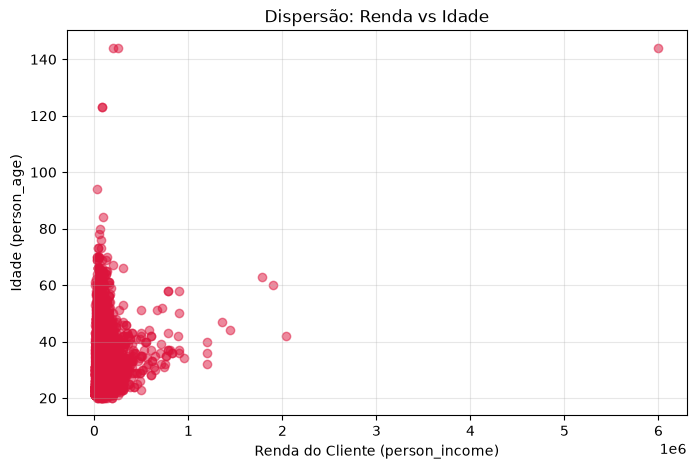

In [36]:
plt.figure(figsize=(8, 5))
plt.scatter(df["person_income"], df["person_age"], alpha=0.5, color="crimson")
plt.title("Dispersão: Renda vs Idade")
plt.xlabel("Renda do Cliente (person_income)")
plt.ylabel("Idade (person_age)")
plt.grid(True, alpha=0.3)
plt.show()


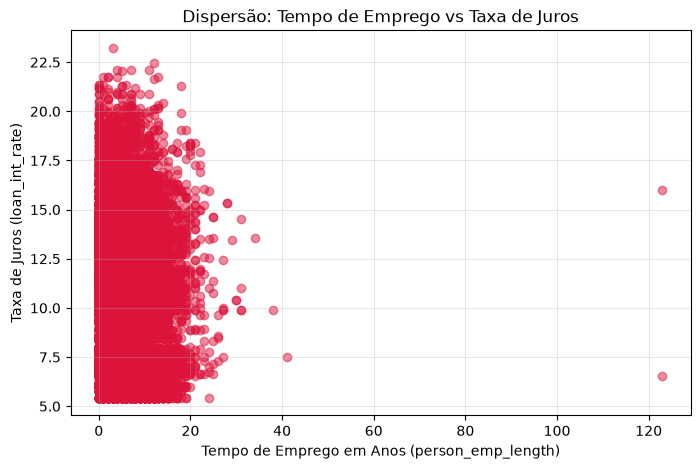

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(df["person_emp_length"], df["loan_int_rate"], alpha=0.5, color="crimson")
plt.title("Dispersão: Tempo de Emprego vs Taxa de Juros")
plt.xlabel("Tempo de Emprego em Anos (person_emp_length)")
plt.ylabel("Taxa de Juros (loan_int_rate)")
plt.grid(True, alpha=0.3)
plt.show()


**Identificação:**
- Encontram-se registros com `person_age > 100` (ex: 123 e 144 anos).
- Encontram-se registros com `person_emp_length > 60` (ex: 123 anos de tempo de emprego).

filtrar a base removendo esses outliers


In [38]:
df_clean = df[(df['person_emp_length'].isna()) | (df['person_emp_length'] <= 60)]
df_clean = df_clean[df_clean['person_age'] <= 100]

print(f"Total de registros originais: {len(df)}")
print(f"Total após remoção de outliers: {len(df_clean)}")
print(f"Outliers removidos: {len(df) - len(df_clean)}")


Total de registros originais: 32581
Total após remoção de outliers: 32574
Outliers removidos: 7


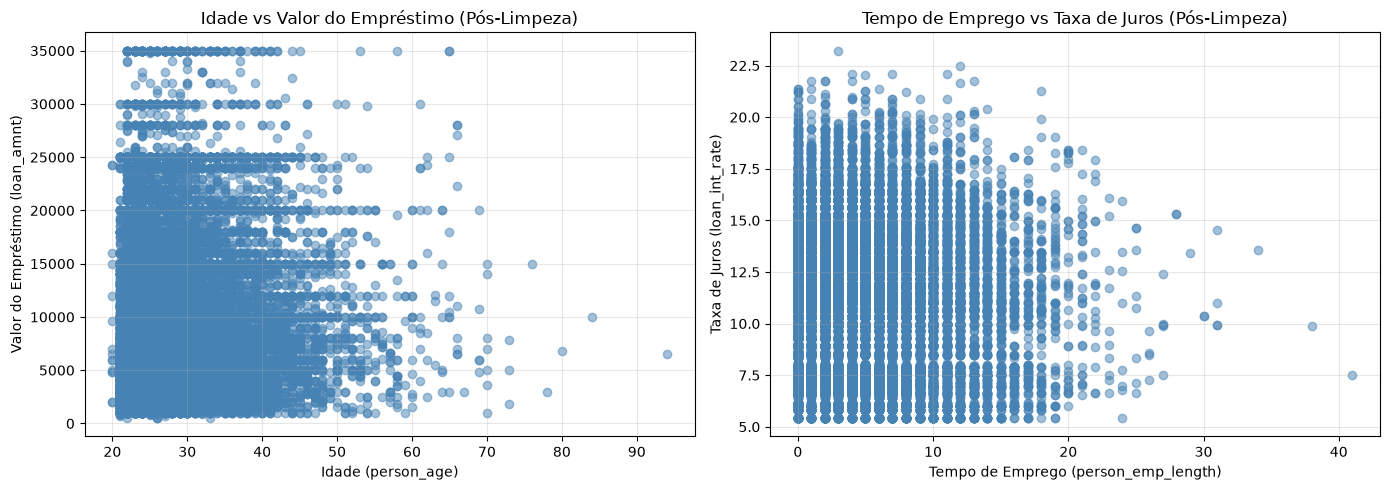

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Idade vs Valor do Empréstimo
axes[0].scatter(df_clean["person_age"], df_clean["loan_amnt"], alpha=0.5, color="steelblue")
axes[0].set_title("Idade vs Valor do Empréstimo (Pós-Limpeza)")
axes[0].set_xlabel("Idade (person_age)")
axes[0].set_ylabel("Valor do Empréstimo (loan_amnt)")
axes[0].grid(True, alpha=0.3)

# Tempo de Emprego vs Taxa de Juros
axes[1].scatter(df_clean["person_emp_length"], df_clean["loan_int_rate"], alpha=0.5, color="steelblue")
axes[1].set_title("Tempo de Emprego vs Taxa de Juros (Pós-Limpeza)")
axes[1].set_xlabel("Tempo de Emprego (person_emp_length)")
axes[1].set_ylabel("Taxa de Juros (loan_int_rate)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Tratamento dos Missing Values

Agora as colunas com dados ausentes e definimos a estratégia adequada para cada uma:
1. Tempo de emprego: Imputação pela mediana dos valores observados.
2. Taxa de juros: Remoção dos registros nulos, evitando viés artificial em variável essencial para precificação de risco.


In [40]:
print("Valores ausentes antes do tratamento:")
print(df_clean[["person_emp_length", "loan_int_rate"]].isnull().sum())

Valores ausentes antes do tratamento:
person_emp_length     895
loan_int_rate        3115
dtype: int64


In [ ]:
# person_emp_length com a mediana
emp_median = df_clean['person_emp_length'].median()
df_clean['person_emp_length'] = df_clean['person_emp_length'].fillna(emp_median)

# removendo os registros onde a taxa de juros (loan_int_rate) é nula
df_clean = df_clean.dropna(subset=['loan_int_rate'])

df_clean = df_clean.reset_index(drop=True)

print("Valores ausentes após o tratamento:")
print(df_clean.isnull().sum())
print(f"\nFormato final do dataset limpo: {df_clean.shape}")

Valores ausentes após o tratamento:
person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Formato final do dataset limpo: (29459, 12)


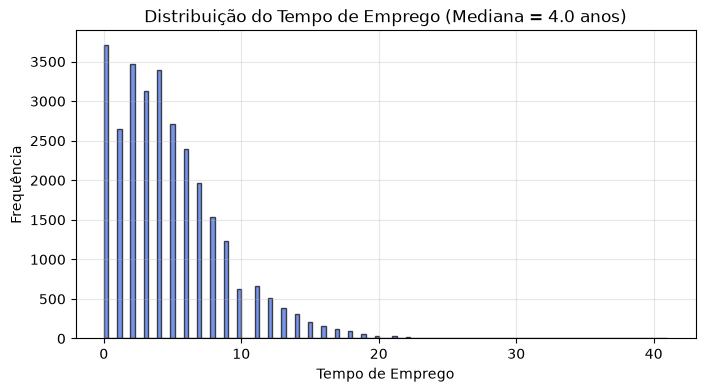

In [42]:
# histograma do tempo de emprego após imputação pela mediana
plt.figure(figsize=(8, 4))
plt.hist(df_clean["person_emp_length"], bins='auto', color='royalblue', edgecolor='black', alpha=0.7)
plt.title(f"Distribuição do Tempo de Emprego (Mediana = {emp_median:.1f} anos)")
plt.xlabel("Tempo de Emprego")
plt.ylabel("Frequência")
plt.grid(True, alpha=0.3)
plt.show()


## 4. Análise Exploratória e Padrões do "loan_status"

> `0 = Adimplente`, `1 = Inadimplente`


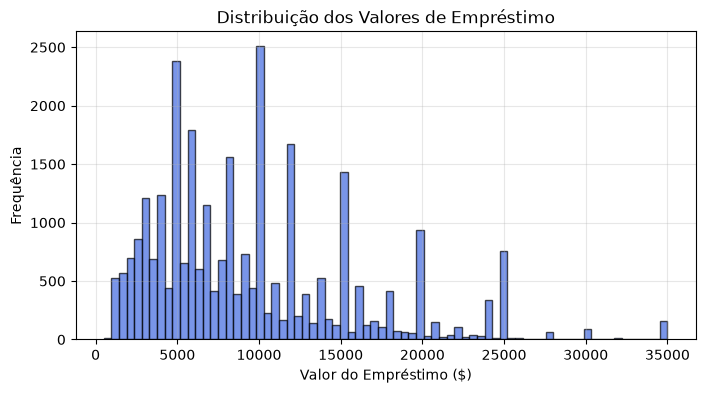

In [43]:
plt.figure(figsize=(8, 4))
plt.hist(df_clean['loan_amnt'], bins='auto', color='royalblue', edgecolor='black', alpha=0.7)
plt.title('Distribuição dos Valores de Empréstimo')
plt.xlabel('Valor do Empréstimo ($)')
plt.ylabel('Frequência')
plt.grid(True, alpha=0.3)
plt.show()

In [46]:
crosstab_intent = pd.crosstab(df_clean['loan_intent'], df_clean['loan_status'], margins=True, margins_name="Total")
crosstab_intent_pct = pd.crosstab(df_clean['loan_intent'], df_clean['loan_status'], normalize='index') * 100

print("Contagem absoluta:")
print(crosstab_intent)
print("\nPercentual por linha (% inadimplência por finalidade):")
crosstab_intent_pct.round(2)

Contagem absoluta:
loan_status            0     1  Total
loan_intent                          
DEBTCONSOLIDATION   3357  1346   4703
EDUCATION           4841  1011   5852
HOMEIMPROVEMENT     2427   863   3290
MEDICAL             3980  1471   5451
PERSONAL            4003  1009   5012
VENTURE             4388   763   5151
Total              22996  6463  29459

Percentual por linha (% inadimplência por finalidade):


loan_status,0,1
loan_intent,,
DEBTCONSOLIDATION,71.38,28.62
EDUCATION,82.72,17.28
HOMEIMPROVEMENT,73.77,26.23
MEDICAL,73.01,26.99
PERSONAL,79.87,20.13
VENTURE,85.19,14.81


In [47]:
# Distribuição da inadimplência por situação de moradia e grau de risco do empréstimo (loan_grade)
pd.crosstab(df_clean['person_home_ownership'], [df_clean['loan_status'], df_clean["loan_grade"]])

loan_status               0                                 1                              
loan_grade                A     B     C    D    E   F  G    A     B    C     D    E   F   G
person_home_ownership                                                                      
MORTGAGE               4722  3325  1736  597  167  33  0  217   294  293   507  141  59  28
OTHER                    21    25    11    9    1   0  0    3     5    5     7    5   2   0
OWN                     787   711   418  243   21   7  0   58    28   24    17   29   8   5
RENT                   3266  3804  2452  494  121  24  1  699  1201  887  1439  396  81  25

In [48]:
# Média do percentual de comprometimento da renda por tipo de moradia e status do empréstimo
crosstab_pct_income = pd.crosstab(
    df_clean["person_home_ownership"], 
    df_clean["loan_status"], 
    values=df_clean["loan_percent_income"], 
    aggfunc="mean"
)
print("Média de comprometimento de renda (loan_percent_income):")
print(crosstab_pct_income.round(4))


Média de comprometimento de renda (loan_percent_income):
loan_status                 0       1
person_home_ownership                
MORTGAGE               0.1464  0.1849
OTHER                  0.1443  0.3022
OWN                    0.1789  0.2965
RENT                   0.1445  0.2645


<Figure size 700x500 with 0 Axes>

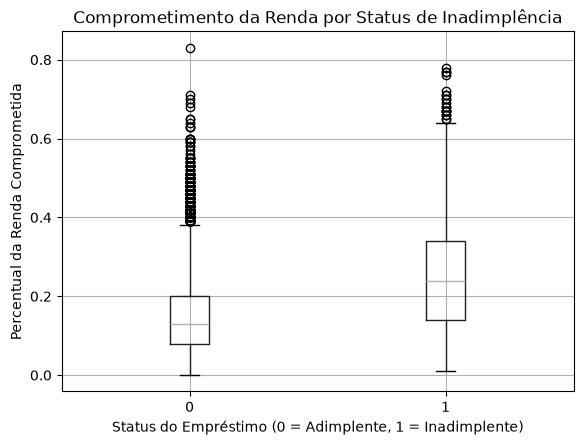

In [49]:
# Boxplot do comprometimento da renda em função do status do empréstimo
plt.figure(figsize=(7, 5))
df_clean.boxplot(column=["loan_percent_income"], by="loan_status", grid=True)
plt.title("Comprometimento da Renda por Status de Inadimplência")
plt.suptitle("")
plt.xlabel("Status do Empréstimo (0 = Adimplente, 1 = Inadimplente)")
plt.ylabel("Percentual da Renda Comprometida")
plt.show()


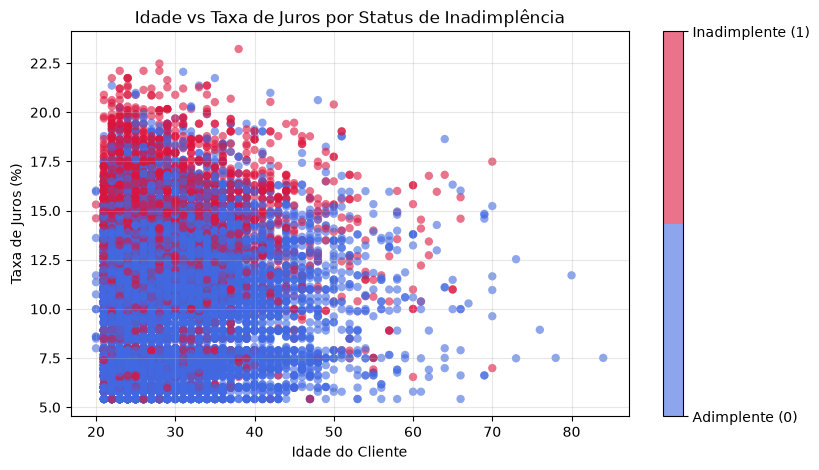

In [50]:
# Dispersão: Idade vs Taxa de Juros categorizada por Status de Inadimplência
plt.figure(figsize=(9, 5))
scatter = plt.scatter(
    df_clean["person_age"], 
    df_clean["loan_int_rate"],
    c=df_clean['loan_status'],
    cmap=matplotlib.colors.ListedColormap(["royalblue", "crimson"]),
    alpha=0.6,
    edgecolors='none'
)
plt.title("Idade vs Taxa de Juros por Status de Inadimplência")
plt.xlabel("Idade do Cliente")
plt.ylabel("Taxa de Juros (%)")
cbar = plt.colorbar(scatter, ticks=[0, 1])
cbar.set_ticklabels(['Adimplente (0)', 'Inadimplente (1)'])
plt.grid(True, alpha=0.3)
plt.show()


## 5. Conclusões e Exportação do Dataset Limpo

### Principais Insights da Análise Exploratória:
1. Outliers: Clientes com idades irreais (>100 anos) e tempos de emprego improváveis (>60 anos) foram expurgados para garantir consistência.
2. Comprometimento de Renda: Clientes inadimplentes apresentam, em média, uma proporção significativamente maior de renda comprometida com o empréstimo (`loan_percent_income`).
3. Taxa de Juros e Risco: Há clara concentração de inadimplência em contratos com taxas de juros mais elevadas e graus de risco mais baixos (`loan_grade` D, E, F, G).
4. Situação de Moradia: Clientes que moram de aluguel (`RENT`) apresentam maior proporção de inadimplência em comparação aos que possuem imóvel próprio (`MORTGAGE` / `OWN`).


In [51]:
# Salvando a base tratada para a modelagem preditiva
clean_path = '../data/cr_loan_clean.csv'
df_clean.to_csv(clean_path, index=False)
print(f"Base tratada salva com sucesso em '{clean_path}'!")
print(f"Dimensões finais: {df_clean.shape}")


Base tratada salva com sucesso em '../data/cr_loan_clean.csv'!
Dimensões finais: (29459, 12)
